In [46]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers
from keras import layers
import os, random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [25]:
SRC = "./data/processing"
IMG_SIZE = 128
BATCH = 32
SEED = 123
AUTOTUNE = tf.data.AUTOTUNE

Comptage sur une époque complète


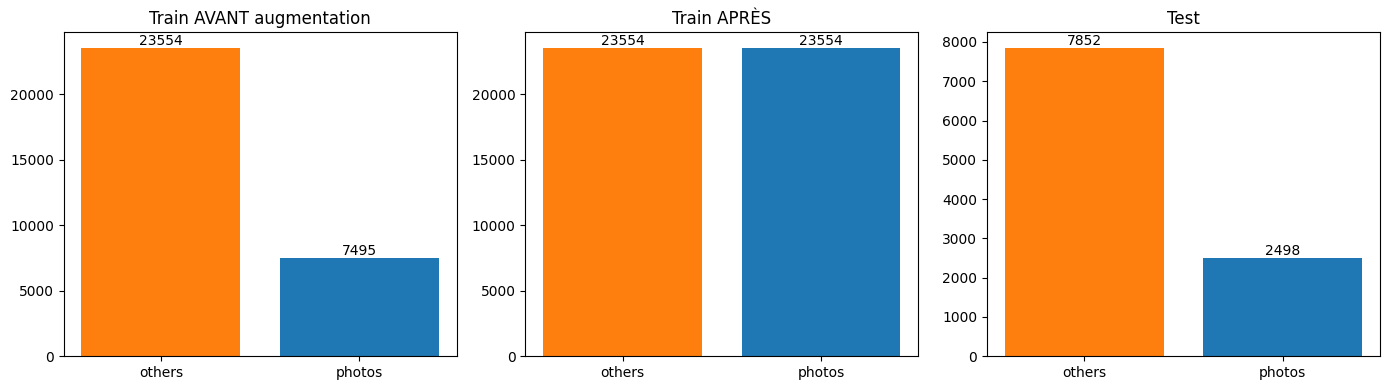

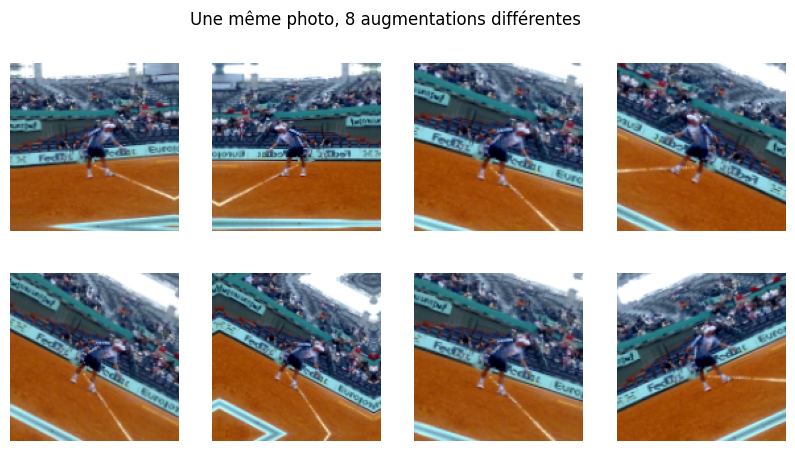

In [ ]:


# 1. Split 75/25 stratifié sur les CHEMINS 
def lister(classe):
    d = os.path.join(SRC, classe)
    return [os.path.join(d, f) for f in os.listdir(d)]

photos, others = lister("photo"), lister("others")   # photos=1, others=0
paths  = photos + others
labels = [1] * len(photos) + [0] * len(others)

p_train_RDA, p_test_RDA, y_train_RDA, y_test_RDA = train_test_split(
    paths, labels, test_size=0.25, stratify=labels, random_state=SEED)

train_photos_RDA = [p for p, y in zip(p_train_RDA, y_train_RDA) if y == 1]
train_others_RDA = [p for p, y in zip(p_train_RDA, y_train_RDA) if y == 0]

# 2. Chargement d'une image
def charger(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, label

# 3. Augmentation à la volée 
augment = tf.keras.Sequential([
    tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

def aug(img, label):
    img = augment(tf.expand_dims(img, 0), training=True)   # (1,128,128,3)
    return tf.squeeze(img, 0), label

n_others = len(train_others_RDA)

ds_others = (tf.data.Dataset.from_tensor_slices((train_others_RDA, [0]*n_others))
             .shuffle(n_others, seed=SEED)
             .map(charger, num_parallel_calls=AUTOTUNE))

# photos : repeat() puis take(n_others) => EXACTEMENT autant que les others
ds_photos = (tf.data.Dataset.from_tensor_slices((train_photos_RDA, [1]*len(train_photos_RDA)))
             .shuffle(len(train_photos_RDA))              # re-mélangé à chaque passage
             .repeat()
             .take(n_others)
             .map(charger, num_parallel_calls=AUTOTUNE)
             .map(aug, num_parallel_calls=AUTOTUNE))  # augmentation différente à chaque copie

# 4. Batchs équilibrés 
half = BATCH // 2

def fusionner(a, b):
    x = tf.concat([a[0], b[0]], axis=0)
    y = tf.concat([a[1], b[1]], axis=0)
    idx = tf.random.shuffle(tf.range(tf.shape(y)[0]))   # mélange dans le batch
    return tf.gather(x, idx), tf.gather(y, idx)

train_ds_RDA = (tf.data.Dataset.zip((ds_others.batch(half), ds_photos.batch(half)))
            .map(fusionner, num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))

test_ds_RDA = (tf.data.Dataset.from_tensor_slices((p_test_RDA, y_test_RDA))
           .map(charger, num_parallel_calls=AUTOTUNE)
           .batch(BATCH).prefetch(AUTOTUNE))

# 5. VÉRIFICATION RÉELLE : on compte les labels qui sortent du pipeline
def compter(ds):
    c = np.zeros(2, dtype=int)
    for _, y in ds:
        c += np.bincount(y.numpy().astype(int), minlength=2)
    return c

print("Comptage sur une époque complète")
c_train = compter(train_ds_RDA)
c_test  = compter(test_ds_RDA)
c_avant = np.array([len(train_others_RDA), len(train_photos_RDA)])

# 6. Affichage
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, c, t in zip(ax, [c_avant, c_train, c_test],
                   ["Train AVANT augmentation", "Train APRÈS", "Test"]):
    bars = a.bar(["others", "photos"], c, color=["tab:orange", "tab:blue"])
    a.bar_label(bars); a.set_title(t)
plt.tight_layout(); plt.show()

# 7. Contrôle visuel : une même photo augmentée 8 fois

img0, _ = charger(train_photos_RDA[0], 1)
fig, ax = plt.subplots(2, 4, figsize=(10, 5))
for a in ax.flat:
    out = augment(img0[None], training=True)[0].numpy()
    a.imshow(out.clip(0, 255).astype("uint8")); a.axis("off")
plt.suptitle("Une même photo, 8 augmentations différentes"); plt.show()

In [44]:
Epoch=50
lambda_l2=0.001
learning_rate=0.01
BATCH_SIZE=32
Dropout:0.1
Patience=5
img_size=64
learning_rate=0.001

In [48]:
"""
Add callback
"""
early_stopping_callback = EarlyStopping(
monitor='val_loss', # The metric to monitor for improvement
patience=Patience,         # Number of epochs with no improvement after which training will be stopped
verbose=1,          # Show a message when stopping
restore_best_weights=True # Restores model weights from the epoch with the best value of the monitored quantity.
)

"""
Load and configure model
"""

model_layers_total = [
    keras.Input(shape=(None, None, 3)), 
    
    # Redimensionnement 
    layers.Resizing(img_size, img_size),

    #Scale to 0 to 1
    layers.Rescaling(1./255),
    
    layers.Conv2D(32, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Dropout(0.1),
]

if img_size == 256: 
    model_layers_total.extend([
        layers.Conv2D(64, (3,3), activation='relu'),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.1),
    ])

model_layers_total.extend([
    layers.Flatten(),
    layers.Dense(128, activation='relu', kernel_regularizer=regularizers.l2(lambda_l2)),
    layers.Dense(1, activation='sigmoid', kernel_regularizer=regularizers.l2(lambda_l2))
])

model_total = keras.Sequential(model_layers_total)
print(model_total.summary())

"""
Configure Optimizer
"""
model_total.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss='binary_crossentropy',
            metrics=['accuracy'])

"""
Launch model
"""
all_callbacks = [early_stopping_callback]
print(f"Lancement du train du modele pour {img_size}x{img_size}")
history_model = model_total.fit(
    train_ds_RDA,
    epochs=Epoch,
    callbacks=all_callbacks,
    validation_data=test_ds_RDA
)


Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing_2 (Resizing)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,281 (6.20 MB)

 Trainable params: 1,625,281 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

None
Lancement du train du modele pour 64x64
Epoch 1/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 2942s 2s/step - accuracy: 0.8394 - loss: 0.3938 - val_accuracy: 0.8043 - val_loss: 0.4405
Epoch 2/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 140s 93ms/step - accuracy: 0.8894 - loss: 0.2995 - val_accuracy: 0.8346 - val_loss: 0.3978
Epoch 3/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 440s 299ms/step - accuracy: 0.9070 - loss: 0.2628 - val_accuracy: 0.8367 - val_loss: 0.4335
Epoch 4/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 305s 206ms/step - accuracy: 0.9198 - loss: 0.2422 - val_accuracy: 0.8348 - val_loss: 0.4383
Epoch 5/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 159s 108ms/step - accuracy: 0.9275 - loss: 0.2219 - val_accuracy: 0.8557 - val_loss: 0.3741
Epoch 6/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 177s 91ms/step - accuracy: 0.9364 - loss: 0.2051 - val_accuracy: 0.8412 - val_loss: 0.4916
Epoch 7/50
1473/1473 ━━━━━━━━━━━━━━━━━━━━ 90s 61ms/step - accuracy: 0.9413 - loss: 0.1918 - val_accuracy: 0.8362 - val_loss: 0.4341
Epoch 8/50
1473/1473 ━━

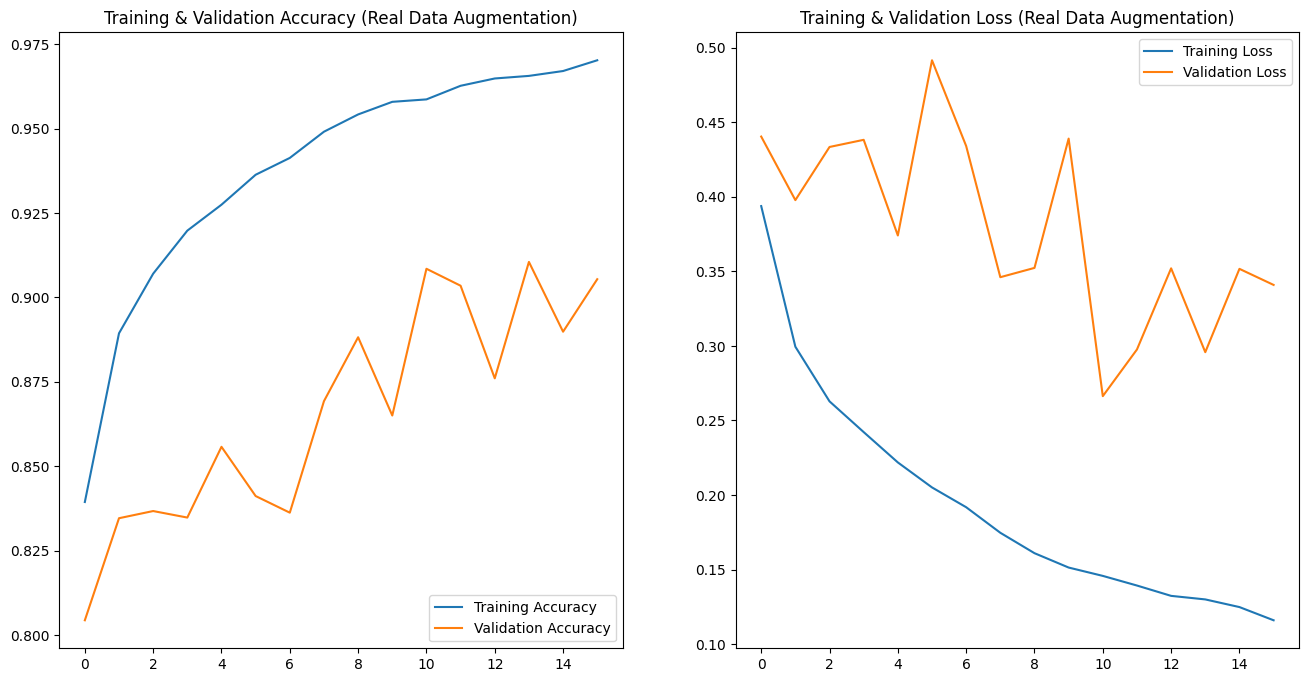

In [50]:
h = history_model.history
epochs_range = range(len(h['accuracy']))

plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, h['accuracy'], label='Training Accuracy')
plt.plot(epochs_range, h['val_accuracy'], label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy (Real Data Augmentation)')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, h['loss'], label='Training Loss')
plt.plot(epochs_range, h['val_loss'], label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss (Real Data Augmentation)')

plt.show()